# Simulatie fuck yeah

hieronder zijn een paar code cells voor setup, die zijn vrij obvious

In [22]:
import model
import numpy as np
import matplotlib.pyplot as plt

In [23]:
# ---------------------------------
#       constantes
# ---------------------------------
r_large = 5 #m
r_small = 2 #m
omega = 0.628 #rad/s
epsilon = -1.765 #rad/s
constants = (r_large, r_small, omega, epsilon)

h_0 = 1 #m - deze wordt niet door accel gebruikt dus ik hou deze apart

## Setup voor variabelen
Hier zet ik de tijd-array neer, en test ik de hoekfunctie. Voel je vrij om de comments weg te halen om de functie te zien.

In [24]:
t = np.linspace(40,120,10000) # time array tussen de lage draai en de verhoging
theta, theta_dot, theta_ddot = model.angle_function(t)
#plt.figure()
#plt.plot(t, theta, 'k.')

position_vector = model.model(t, *constants, theta, h_0)
r_x = position_vector[0]
r_y = position_vector[1]
r_z = position_vector[2]

#plot voor y ziet er goed uit, uit de andere twee kan je niet veel opmaken
#plt.figure()
#plt.plot(t, r_y)
#plt.figure()
#plt.plot(t, r_x)
#plt.plot(t, r_z, 'g')

## trajectory in het horizontale vlak
De volgende code is VOLLEDIG door ChatGPT gegenereerd en bestaat puur zodat ik naar de trajectory kan kijken.

Slider werkt helaas niet want matplotlib widget heeft kanker as usual

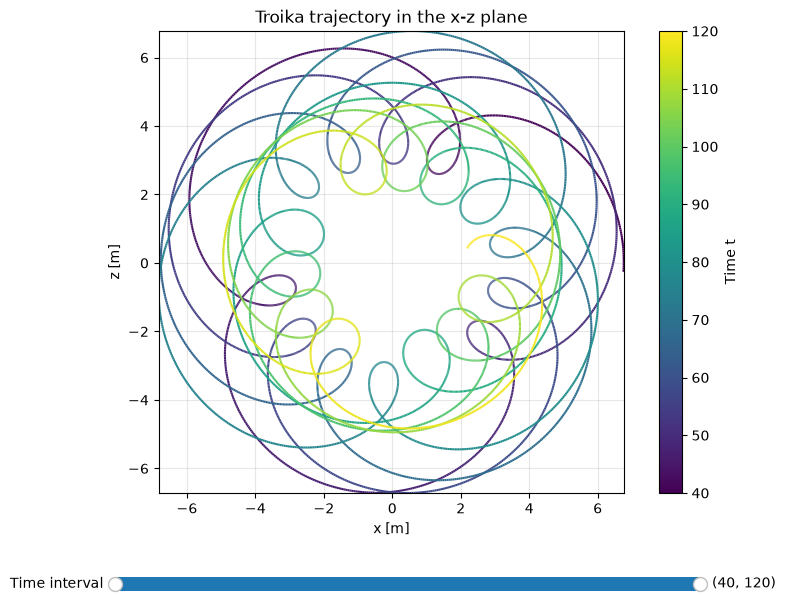

In [25]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.widgets import RangeSlider

# Create the figure and trajectory axes
fig, ax = plt.subplots(figsize=(9, 7))
plt.subplots_adjust(bottom=0.22)

# Create line segments from consecutive points in the x,z plane
points = np.column_stack((r_x, r_z))
segments = np.stack([points[:-1], points[1:]], axis=1)

# Color each segment according to its midpoint in time
t_mid = (t[:-1] + t[1:]) / 2

trajectory = LineCollection(
    segments,
    cmap="viridis",
    norm=plt.Normalize(t.min(), t.max())
)
trajectory.set_array(t_mid)
trajectory.set_linewidth(1.5)

ax.add_collection(trajectory)

# Set plot boundaries
ax.set_xlim(np.min(r_x), np.max(r_x))
ax.set_ylim(np.min(r_z), np.max(r_z))
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("x [m]")
ax.set_ylabel("z [m]")
ax.set_title("Troika trajectory in the x-z plane")
ax.grid(True, alpha=0.3)

# Colorbar representing time
cbar = fig.colorbar(trajectory, ax=ax)
cbar.set_label("Time t")

# Add an interactive time-range slider
slider_ax = fig.add_axes([0.18, 0.07, 0.65, 0.04])

time_slider = RangeSlider(
    slider_ax,
    "Time interval",
    float(t.min()),
    float(t.max()),
    valinit=(float(t.min()), float(t.max())),
    valstep=float(t[1] - t[0])
)

def update(val):
    t_min, t_max = time_slider.val

    # Select points inside the chosen time interval
    mask = (t >= t_min) & (t <= t_max)
    selected_points = np.column_stack((r_x[mask], r_z[mask]))
    selected_t = t[mask]

    # Rebuild the trajectory segments
    if len(selected_points) >= 2:
        selected_segments = np.stack(
            [selected_points[:-1], selected_points[1:]],
            axis=1
        )
        trajectory.set_segments(selected_segments)
        trajectory.set_array(
            (selected_t[:-1] + selected_t[1:]) / 2
        )
    else:
        trajectory.set_segments([])
        trajectory.set_array(np.array([]))

    fig.canvas.draw_idle()

time_slider.on_changed(update)

plt.show()


# acceleration
Hier doen we het voor: nu is het tijd om acceleration te plotten.

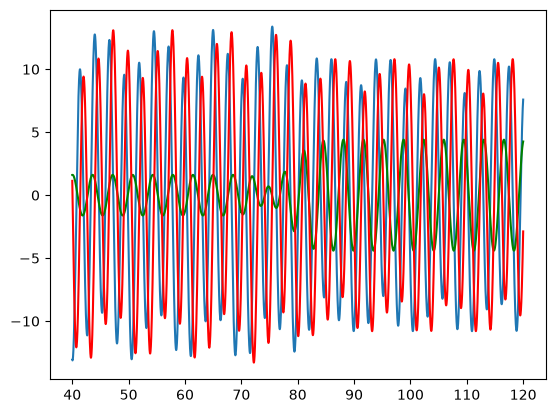

In [26]:
accel_vector = model.model_acceleration(t, *constants, h_0, 0, theta, theta_dot, theta_ddot)
a_x, a_y, a_z = accel_vector

plt.figure()
plt.plot(t, a_x)
plt.plot(t, a_y, 'g')
plt.plot(t,a_z, 'r')

## afgeleide test
Deze cell is een test om te checken of de afgeleide correct is, want de acceleratie is onlogisch groot.

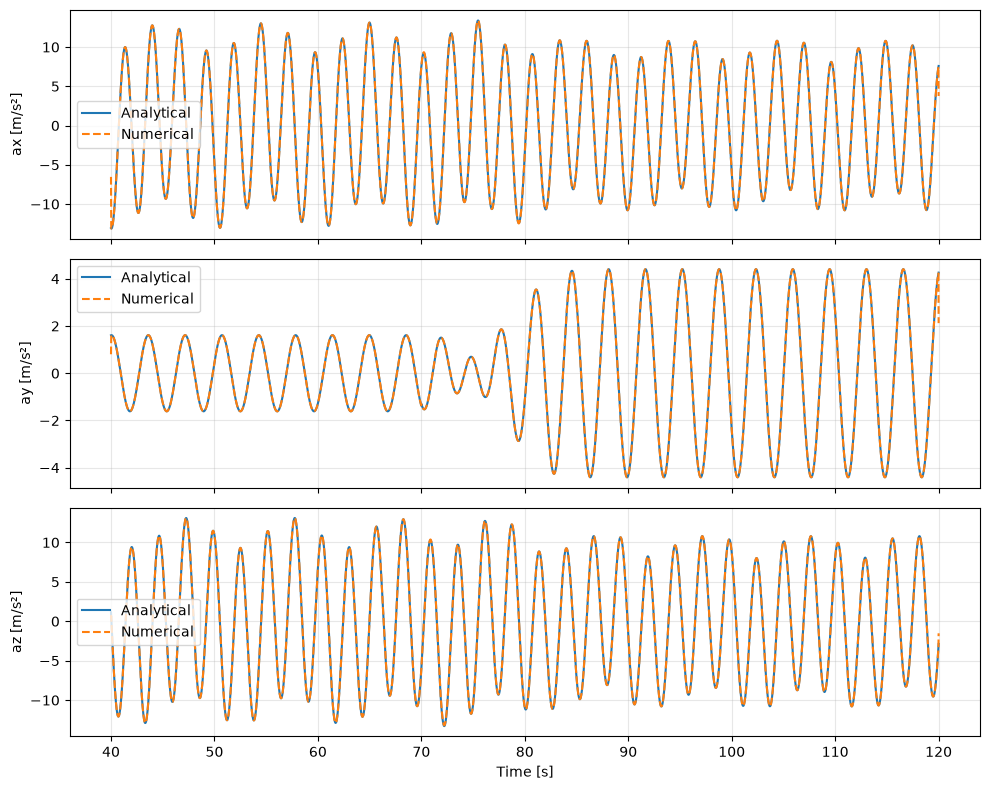

In [27]:
position_vector = model.model(t, *constants, theta, h_0)

acceleration_numeric = np.gradient(
    np.gradient(position_vector, t, axis=1),
    t,
    axis=1
)

labels = ["x", "y", "z"]

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(t, accel_vector[i], label="Analytical")
    ax.plot(t, acceleration_numeric[i], "--", label="Numerical")
    ax.set_ylabel(f"a{labels[i]} [m/s²]")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()